In [136]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [137]:
df=pd.read_csv("/content/data.csv")

In [138]:
df.head()

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,country
0,2014-05-02 00:00:00,313000.0,3.0,1.50,1340,7912,1.5,0,0,3,1340,0,1955,2005,18810 Densmore Ave N,Shoreline,WA 98133,USA
1,2014-05-02 00:00:00,2384000.0,5.0,2.50,3650,9050,2.0,0,4,5,3370,280,1921,0,709 W Blaine St,Seattle,WA 98119,USA
2,2014-05-02 00:00:00,342000.0,3.0,2.00,1930,11947,1.0,0,0,4,1930,0,1966,0,26206-26214 143rd Ave SE,Kent,WA 98042,USA
3,2014-05-02 00:00:00,420000.0,3.0,2.25,2000,8030,1.0,0,0,4,1000,1000,1963,0,857 170th Pl NE,Bellevue,WA 98008,USA
4,2014-05-02 00:00:00,550000.0,4.0,2.50,1940,10500,1.0,0,0,4,1140,800,1976,1992,9105 170th Ave NE,Redmond,WA 98052,USA


In [139]:
df.shape

(4600, 18)

In [140]:
df.isnull().sum()

,0
date,0
price,0
bedrooms,0
bathrooms,0
sqft_living,0
sqft_lot,0
floors,0
waterfront,0
view,0
condition,0


no null values detected

In [141]:
df.dtypes

,0
date,object
price,float64
bedrooms,float64
bathrooms,float64
sqft_living,int64
sqft_lot,int64
floors,float64
waterfront,int64
view,int64
condition,int64


selecting features as X and Y

In [142]:
correlation = df.corr(numeric_only=True)

price_corr = correlation['price'].sort_values(ascending=False)

print(price_corr)

price            1.000000
sqft_living      0.430410
sqft_above       0.367570
bathrooms        0.327110
view             0.228504
sqft_basement    0.210427
bedrooms         0.200336
floors           0.151461
waterfront       0.135648
sqft_lot         0.050451
condition        0.034915
yr_built         0.021857
yr_renovated    -0.028774
Name: price, dtype: float64


as sqft_living cloumn has high corelation selecting that column as input feature and target as price

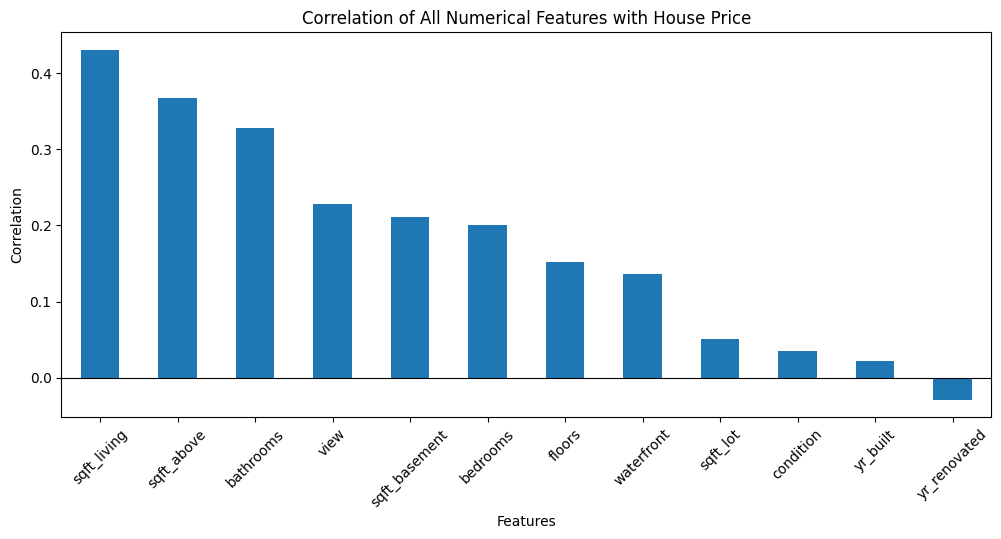

In [143]:
import matplotlib.pyplot as plt

price_corr.drop('price').plot(
    kind='bar',
    figsize=(12, 5)
)

plt.title('Correlation of All Numerical Features with House Price')
plt.xlabel('Features')
plt.ylabel('Correlation')
plt.xticks(rotation=45)
plt.axhline(y=0, color='black', linewidth=0.8)

plt.show()

feature and target selection

In [144]:
X = df[['sqft_living']]
y = df['price']

performing basic EDA

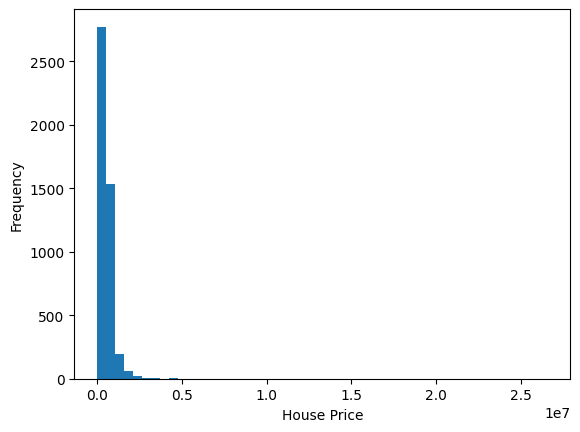

In [145]:
import matplotlib.pyplot as plt

plt.hist(df['price'], bins=50)
plt.xlabel('House Price')
plt.ylabel('Frequency')
plt.show()

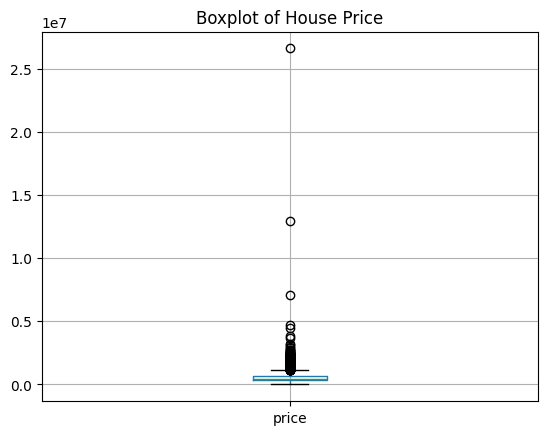

In [146]:
df.boxplot(column='price')
plt.title('Boxplot of House Price')
plt.show()

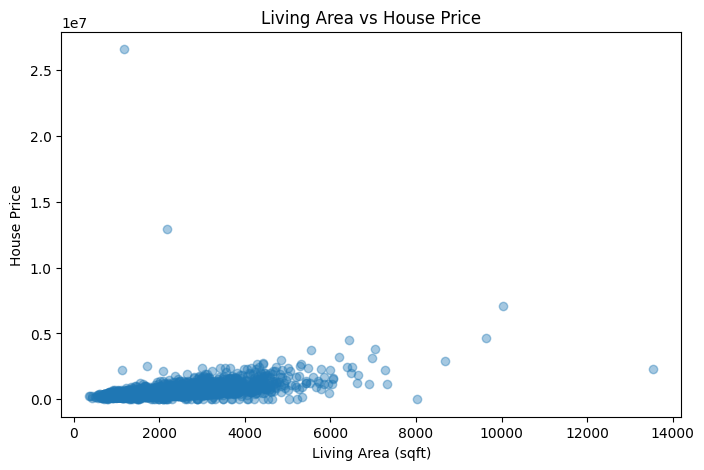

In [147]:
plt.figure(figsize=(8,5))

plt.scatter(X, y, alpha=0.4)

plt.xlabel('Living Area (sqft)')
plt.ylabel('House Price')
plt.title('Living Area vs House Price')

plt.show()

In [148]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

trained the model without scaling

In [149]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [150]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train_scaled, y_train)

LinearRegression()

In [151]:
y_pred = model.predict(X_test_scaled)

In [152]:
print("Coefficient:", model.coef_[0])

print("Intercept:", model.intercept_)

Coefficient: 256157.88513574467
Intercept: 544848.268832546


trained the model with scaling

In [153]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model1 = LinearRegression()

model1.fit(X_train_scaled, y_train)

y_pred = model1.predict(X_test_scaled)

In [154]:
print("Coefficient:", model1.coef_[0])

print("Intercept:", model1.intercept_)

Coefficient: 256157.88513574467
Intercept: 544848.268832546


In [155]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

print("MAE:", mean_absolute_error(y_test, y_pred))

print("MSE:", mean_squared_error(y_test, y_pred))

print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))

print("R2:", r2_score(y_test, y_pred))

MAE: 225375.25345857348
MSE: 990204087727.1417
RMSE: 995089.9897633087
R2: 0.029065410341410414


the model is performing poorly as the r2 score is 0.02

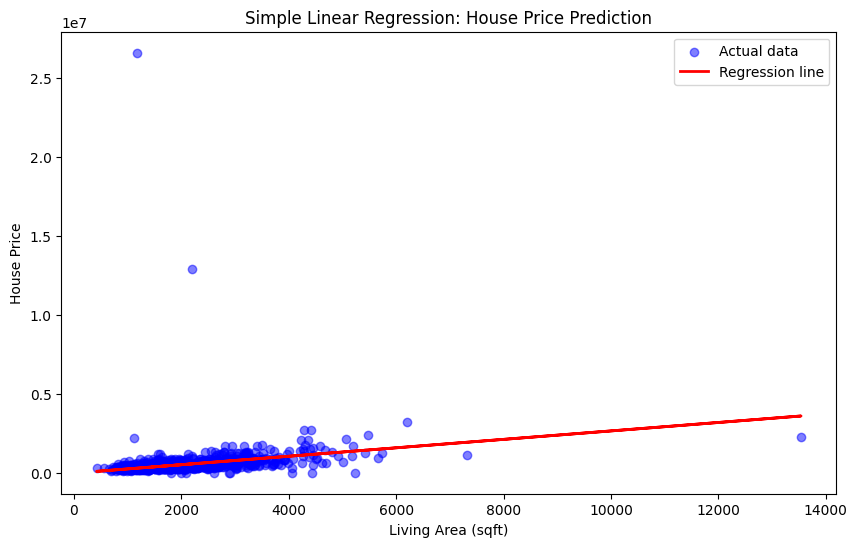

In [156]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

# Actual data points
plt.scatter(X_test, y_test, color='blue', alpha=0.5, label='Actual data')

# Regression line
plt.plot(X_test, y_pred, color='red', linewidth=2, label='Regression line')

plt.xlabel('Living Area (sqft)')
plt.ylabel('House Price')
plt.title('Simple Linear Regression: House Price Prediction')

plt.legend()
plt.show()

checking the model for new input

In [157]:
new_house = pd.DataFrame({
    'sqft_living': [2000]
})

predicted_price = model.predict(new_house)

print("Predicted House Price:", predicted_price[0])


Predicted House Price: 512860618.5403219


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LinearRegression was fitted without feature names
  warnings.warn(
